Calculating regression model metrics - exercise 2

1. Load the dataset from the exercise "Linear Regression - exercise 2" (diamonds.csv). Open the solution file for the same exercise in Google Colab.
2. Import all the necessary methods from the corresponding module of the Scikit-learn library, which will enable you to calculate the metrics indicated below.
3. Run all the cells with the code one by one, from loading the data into the data frame to training and predicting the linear regression model.
4. Make a prediction on the training set (X_train) and store the result under the variable y_pred_train.
5. For the training and test data, calculate the metrics: R2, adjusted R2, MAE, MSE and RMSE. Display them in a readable form. Based on R2, can we conclude that the model is better after data processing?

In [2]:
import pandas as pd

diamonds_df = pd.read_csv("data/diamonds_preprocessed.csv")
diamonds_df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,2,1,3,61.5,55.0,326,3.95,3.98,2.43
1,0.21,3,1,2,59.8,61.0,326,3.89,3.84,2.31
2,0.23,1,1,4,56.9,65.0,327,4.05,4.07,2.31
3,0.29,3,5,5,62.4,58.0,334,4.20,4.23,2.63
4,0.31,1,6,3,63.3,58.0,335,4.34,4.35,2.75


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = diamonds_df.drop("price", axis=1)
y = diamonds_df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

y_pred = lin_reg.predict(X_test)
lin_reg.score(X_test, y_test)

0.8892348217787043

In [ ]:
# Predict prices for the training rows that the model learned from.
# Compare these predictions with the test-set predictions to check generalization.
y_pred_train = lin_reg.predict(X_train)

In [13]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# MAE is the average absolute prediction error, measured in dollars.
# Compare training and test MAE using predictions from their matching datasets.

mae_train = mean_absolute_error(y_train, y_pred_train)
mae_test = mean_absolute_error(y_test, y_pred)

print(f"MAE_train result:\t${mae_train}")
print(f"MAE_test result:\t${mae_test}")

MAE_train result:	$864.2664814836187
MAE_test result:	$847.0175164392709


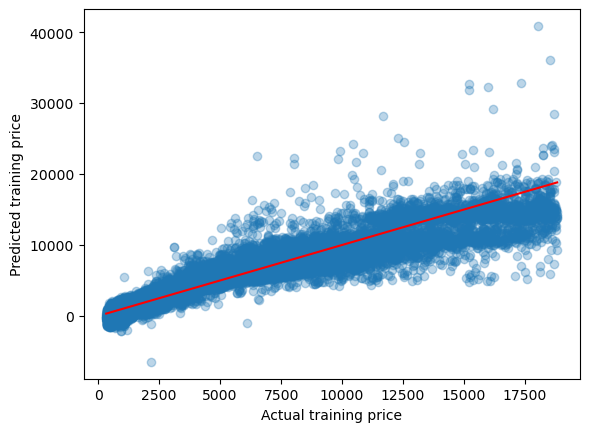

In [12]:
import matplotlib.pyplot as plt

plt.scatter(y_train, y_pred_train, alpha=0.3)
plt.plot([y_train.min(), y_train.max()],
         [y_train.min(), y_train.max()],
         color="red")
plt.xlabel("Actual training price")
plt.ylabel("Predicted training price")
plt.show()

In [ ]:
# MSE averages squared errors, so large prediction errors count more heavily.

mse_train = mean_squared_error(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred)

print(f"MSE_train result:\t${mse_train}")
print(f"MSE_test result:\t${mse_test}")

MSE_train result:	$1844784.6474167109
MSE_test result:	$1686884.9464028704


In [15]:
# RMSE is the square root of MSE and is expressed in the target's units (dollars).
rmse_train = np.sqrt(mse_train)
rmse_test = np.sqrt(mse_test)
print(f"Training RMSE: ${rmse_train:,.2f}")
print(f"Test RMSE: ${rmse_test:,.2f}")

Training RMSE: $1,358.23
Test RMSE: $1,298.80


In [16]:
# R2 measures how much better predictions are than using the split's mean price.
# A higher value is better; compare train and test to assess generalization.
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred)
print(f"Training R2: {r2_train:.4f}")
print(f"Test R2: {r2_test:.4f}")

Training R2: 0.8860
Test R2: 0.8892


In [17]:
# Adjusted R2 penalizes R2 for the number of predictors in the model.
def adjusted_r2_score(r2, n, k):
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))

# Use each split's sample count and the number of input features.
number_of_features = X_train.shape[1]
adjusted_r2_train = adjusted_r2_score(
    r2_train, len(y_train), number_of_features
)
adjusted_r2_test = adjusted_r2_score(
    r2_test, len(y_test), number_of_features
)
print(f"Training adjusted R2: {adjusted_r2_train:.4f}")
print(f"Test adjusted R2: {adjusted_r2_test:.4f}")

Training adjusted R2: 0.8860
Test adjusted R2: 0.8892
